# Кластеризация и снижение размерности

## Содержание

0. Подготовка среды и подключение Weights & Biases
1. Данные и постановка задачи без учителя
2. Метод k-средних (k-means)
3. Другие методы: иерархическая кластеризация и DBSCAN
4. Снижение размерности: метод главных компонент (PCA)
5. Практикум

До сих пор у нас была **разметка**: мы предсказывали известную целевую переменную. Теперь переходим к **обучению без учителя** — размечать данные нужно самим. Сначала группируем объекты на похожие (кластеризация), затем учимся сжимать много признаков в несколько главных направлений (снижение размерности), чтобы данные было проще увидеть и описать.

Демонстрационный пример — датасет о химическом составе вин (три сорта). Практикум (раздел 5) вы выполняете на **датасете своего проекта**. Выводы после каждого блока записывайте **в ячейке markdown прямо в блокноте**.

## 0. Подготовка среды и подключение Weights & Biases

К библиотекам прошлых занятий добавляется `scipy` для дендрограммы. **Примечание.** Если с W&B проблемы, замените `wandb.init(...)` на `wandb.init(mode="disabled")`.

In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

import wandb

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)
RANDOM_STATE = 42
wandb.login()

True

## 1. Данные и постановка задачи без учителя

Датасет `load_wine` содержит результаты химического анализа 178 образцов вина; у каждого — 13 числовых признаков (содержание алкоголя, магний, фенолы и т.д.). Известен и истинный сорт (их три), но в обучении без учителя мы эту метку **не используем** — она понадобится только в конце, чтобы проверить, насколько кластеры совпали с реальными сортами.

**Постановка.** Дана матрица объектов $X$ без целевой переменной. Нужно разбить объекты на группы так, чтобы внутри группы объекты были похожи, а между группами — отличались.

**Важно:** кластеризация и снижение размерности чувствительны к масштабу признаков, поэтому признаки стандартизуем.

In [2]:
wine = load_wine(as_frame=True)
X = wine.data
y_true = wine.target  # только для проверки в конце, в кластеризации НЕ используется

print("Размер таблицы:", X.shape)
print("Истинные классы:", np.bincount(y_true))
X.describe().loc[['mean', 'std', 'min', 'max']].round(2)

Размер таблицы: (178, 13)
Истинные классы: [59 71 48]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


In [3]:
# Масштаб признаков очень разный — без стандартизации k-means и PCA «поедут»
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
print("После стандартизации: mean ≈ 0, std ≈ 1 для каждого признака")

После стандартизации: mean ≈ 0, std ≈ 1 для каждого признака


## 2. Метод k-средних (k-means)

### Математический аппарат

Алгоритм задаёт $k$ центров $\mu_1, \dots, \mu_k$ и минимизирует **внутрикластерную сумму квадратов** (WCSS, она же инерция):

$$J = \sum_{i=1}^{n} \lVert x_i - \mu_{c(i)} \rVert^2 \to \min,$$

где $c(i)$ — номер кластера объекта $x_i$. Минимум ищут итеративно (**алгоритм Ллойда**): назначить каждый объект ближайшему центру → пересчитать центры как средние → повторять. Каждый шаг не увеличивает $J$, поэтому процесс сходится (к локальному минимуму).

**Как выбрать $k$.** Инерция $J$ всегда падает с ростом $k$ (при $k=n$ она равна нулю), поэтому «минимум $J$» не годится. Используют:

- **метод локтя** — искать излом на графике $J(k)$;
- **силуэт** $s = \dfrac{b - a}{\max(a, b)}$, где $a$ — среднее расстояние до объектов своего кластера, $b$ — до ближайшего чужого. $s \in [-1, 1]$, больше — лучше.

**Примечание.** Кластеры k-means по построению круглые и сравнимые по размеру; на вытянутых или плотностных структурах метод работает плохо — тогда смотрите раздел 3.

In [4]:
km = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
labels = km.fit_predict(Xs)

print("Инерция:", round(km.inertia_, 1))
print("Силуэт:", round(silhouette_score(Xs, labels), 3))
print("Совпадение с истинными сортами (ARI):", round(adjusted_rand_score(y_true, labels), 3))

# сопоставим кластеры и истинные классы
print("\nТаблица соответствия (кластер × истинный сорт):")
print(pd.crosstab(labels, y_true))

Инерция: 1277.9
Силуэт: 0.285
Совпадение с истинными сортами (ARI): 0.897

Таблица соответствия (кластер × истинный сорт):
target   0   1   2
row_0             
0        0  65   0
1        0   3  48
2       59   3   0


 k  inertia  silhouette
 2 1658.759       0.259
 3 1277.928       0.285
 4 1175.428       0.260
 5 1109.513       0.202
 6 1046.002       0.237


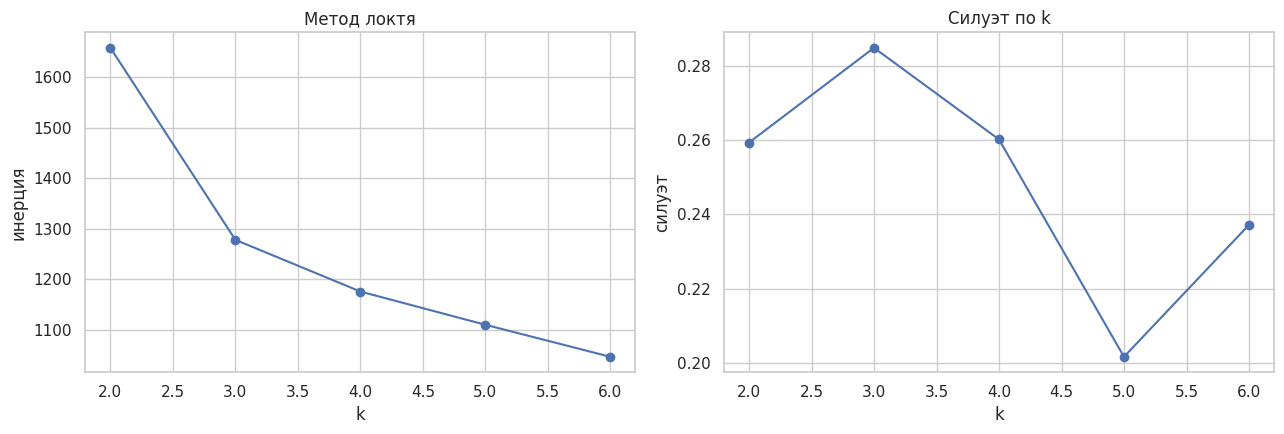

In [5]:
# Выбор k: инерция (локоть) и силуэт
rows = []
for k in [2, 3, 4, 5, 6]:
    m = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
    rows.append((k, m.inertia_, silhouette_score(Xs, m.labels_)))

k_table = pd.DataFrame(rows, columns=['k', 'inertia', 'silhouette'])
print(k_table.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_table['k'], k_table['inertia'], marker='o')
axes[0].set_xlabel('k'); axes[0].set_ylabel('инерция'); axes[0].set_title('Метод локтя')
axes[1].plot(k_table['k'], k_table['silhouette'], marker='o')
axes[1].set_xlabel('k'); axes[1].set_ylabel('силуэт'); axes[1].set_title('Силуэт по k')
plt.tight_layout(); plt.show()

**Задача 1.**
Какому $k$ соответствует излом на графике инерции и максимум силуэта? Сколько образцов оказалось «не в своём» кластере по сравнению с истинными сортами? Сделайте вывод — в «Выводе».

In [6]:
from itertools import permutations

tab = pd.crosstab(labels, y_true)
matches = max(sum(tab.iloc[i, p[i]] for i in range(3)) for p in permutations(range(3)))
print("Совпало после сопоставления кластеров:", matches, "из", len(y_true))
print("Несовпадений:", len(y_true) - matches)


Совпало после сопоставления кластеров: 172 из 178
Несовпадений: 6


**Вывод:**

Излом инерции и максимум силуэта находятся при $k=3$. После сопоставления номеров кластеров с истинными сортами совпали 172 из 178 образцов, 6 не совпали. ARI равен 0.897, значит группы хорошо, но не идеально соответствуют сортам.

## 3. Другие методы: иерархическая кластеризация и DBSCAN

### Математический аппарат

- **Иерархическая (агломеративная) кластеризация** последовательно объединяет ближайшие объекты/группы. Результат удобно изображать **дендрограммой**; число кластеров выбирают, «разрезая» дерево на нужной высоте. Расстояние между кластерами задаётся связью (ward, average, complete).
- **DBSCAN** — плотностный метод: кластеры — это области высокой плотности, разделённые областями низкой. Ему нужно два параметра: радиус `eps` и минимум соседей `min_samples`. Он сам определяет число кластеров и **помечает выбросы** меткой `-1`, но плохо работает, когда плотность кластеров сильно разная.

**Смысл:** у разных методов разные представления о «похожести»: k-means делит по расстоянию до центра, иерархия — по цепочке слияний, DBSCAN — по плотности. Выбор метода зависит от формы кластеров.

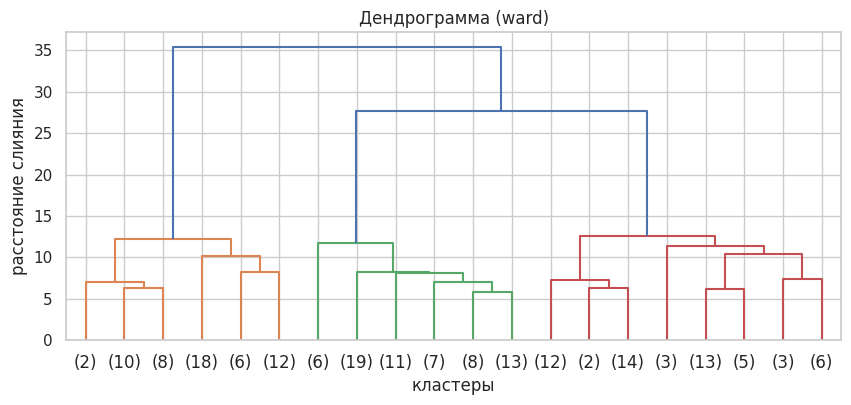

Агломеративная (3): ARI = 0.79 | силуэт = 0.277


In [7]:
# Агломеративная кластеризация + дендрограмма
Z = linkage(Xs, method='ward')
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode='lastp', p=20, show_leaf_counts=True)
plt.title('Дендрограмма (ward)')
plt.xlabel('кластеры'); plt.ylabel('расстояние слияния')
plt.show()

ag = AgglomerativeClustering(n_clusters=3).fit(Xs)
print("Агломеративная (3): ARI =", round(adjusted_rand_score(y_true, ag.labels_), 3),
      "| силуэт =", round(silhouette_score(Xs, ag.labels_), 3))

In [8]:
# DBSCAN: перебор eps (min_samples фиксирован)
for eps in [1.5, 2.0, 2.5]:
    db = DBSCAN(eps=eps, min_samples=5).fit(Xs)
    labs = db.labels_
    n_clusters = len(set(labs)) - (1 if -1 in labs else 0)
    noise = int((labs == -1).sum())
    ari = adjusted_rand_score(y_true, labs) if n_clusters > 1 else float('nan')
    print(f"eps={eps}: кластеров={n_clusters}, выбросов={noise}, ARI={ari:.3f}")

eps=1.5: кластеров=0, выбросов=178, ARI=nan
eps=2.0: кластеров=5, выбросов=85, ARI=0.220
eps=2.5: кластеров=1, выбросов=24, ARI=nan


**Задача 2.**
Сравните k-means, агломеративную кластеризацию и DBSCAN по ARI и силуэту. Какой метод лучше совпал с истинными сортами и почему? Что DBSCAN считает выбросами? Ответ — в «Выводе».

In [9]:
rows = [("k-means", 3, adjusted_rand_score(y_true, labels), silhouette_score(Xs, labels), 0),
        ("Агломеративная", 3, adjusted_rand_score(y_true, ag.labels_), silhouette_score(Xs, ag.labels_), 0)]
for eps in [1.5, 2.0, 2.5]:
    labs = DBSCAN(eps=eps, min_samples=5).fit_predict(Xs)
    mask = labs != -1
    n = len(set(labs[mask]))
    sil = silhouette_score(Xs[mask], labs[mask]) if n > 1 else np.nan
    ari = adjusted_rand_score(y_true, labs) if n > 1 else np.nan
    rows.append((f"DBSCAN {eps}", n, ari, sil, int((~mask).sum())))
print(pd.DataFrame(rows, columns=["Метод", "Кластеров", "ARI", "Силуэт без выбросов", "Выбросов"]).round(3).to_string(index=False))


         Метод  Кластеров   ARI  Силуэт без выбросов  Выбросов
       k-means          3 0.897                0.285         0
Агломеративная          3 0.790                0.277         0
    DBSCAN 1.5          0   NaN                  NaN       178
    DBSCAN 2.0          5 0.220                0.240        85
    DBSCAN 2.5          1   NaN                  NaN        24


**Вывод:**

Лучше всего с истинными сортами совпал k-means: ARI = 0.897 и силуэт = 0.285. У агломеративного метода ARI = 0.790 и силуэт = 0.277. При `eps=2.0` DBSCAN выделяет 5 кластеров, 85 образцов считает выбросами; ARI = 0.220, силуэт оставшихся объектов = 0.240. При `eps=1.5` все образцы помечены как шум, а при `eps=2.5` остаётся один кластер. Выбросы DBSCAN — объекты без достаточного числа соседей в заданном радиусе, а не обязательно ошибки данных.


## 4. Снижение размерности: метод главных компонент (PCA)

### Математический аппарат

Идея PCA — найти такие направления в пространстве признаков, вдоль которых данные разбросаны сильнее всего, и спроецировать объекты на несколько первых из них. Пусть признаки центрированы, а $C = \frac{1}{n}X^\top X$ — ковариационная матрица. Тогда главные компоненты — это **собственные векторы** $C$, а соответствующие собственные значения равны дисперсиям вдоль этих направлений:

$$C v_j = \lambda_j v_j, \qquad \lambda_1 \ge \lambda_2 \ge \dots$$

**Объяснённая дисперсия** доли $j$ — это $\lambda_j / \sum_i \lambda_i$. Оставляя первые 2 компоненты, мы теряем часть информации, но получаем плоскую картинку для визуализации.

*Смысл:* PCA не использует метки — это тоже обучение без учителя. Он полезен для визуализации, шумоподавления и ускорения последующих моделей, но новые признаки — это линейные комбинации исходных и их не так просто интерпретировать.

**Задача 3 (на вывод).**
Покажите, что первая главная компонента максимизирует дисперсию проекции $\mathrm{Var}(Xv)$ при $\lVert v \rVert = 1$, и что решение — собственный вектор ковариационной матрицы с наибольшим собственным значением.

Объяснённая дисперсия по компонентам: [np.float64(0.362), np.float64(0.192)]
Суммарно двумя компонентами: 0.554


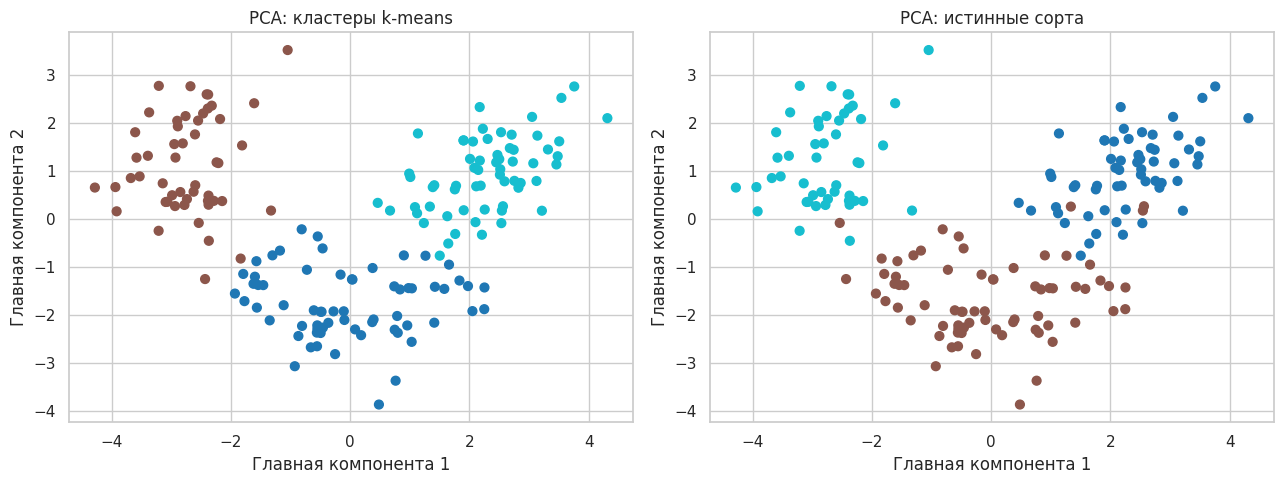

In [10]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(Xs)

print("Объяснённая дисперсия по компонентам:", [round(v, 3) for v in pca.explained_variance_ratio_])
print("Суммарно двумя компонентами:", round(pca.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='tab10', s=40)
axes[0].set_title('PCA: кластеры k-means')
axes[0].set_xlabel('Главная компонента 1'); axes[0].set_ylabel('Главная компонента 2')
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap='tab10', s=40)
axes[1].set_title('PCA: истинные сорта')
axes[1].set_xlabel('Главная компонента 1'); axes[1].set_ylabel('Главная компонента 2')
plt.tight_layout(); plt.show()

In [11]:
# Логируем k-means в W&B
run = wandb.init(project="apml-course", name="kmeans-wine", config={"k": 3})
wandb.log({"inertia": km.inertia_, "silhouette": silhouette_score(Xs, labels)})
run.finish()

**Ваш вывод:**

Для единичного вектора $v$ дисперсия проекции равна $\mathrm{Var}(Xv)=v^	op C v$. По разложению $C=Q\Lambda Q^	op$ это выражение является взвешенной суммой собственных значений, где веса неотрицательны и суммируются до 1. Максимум достигается при направлении собственного вектора, соответствующего наибольшему собственному значению $\lambda_1$; тогда дисперсия равна $\lambda_1$.


## 5. Практикум

Задания выполняются на **датасете своего проекта**. Кластеризация не требует целевой переменной, поэтому берите числовые признаки (категориальные предварительно закодируйте one-hot). После каждого задания заполните ячейку **«Вывод»**.

### Задание 5.1. Подготовка признаков

Выберите набор признаков для кластеризации, обработайте пропуски и стандартизуйте. Объясните, почему для k-means и PCA масштабирование обязательно.

In [12]:
glass = pd.read_csv("glass.csv")
X_glass = glass.select_dtypes(include=np.number).drop(columns=["Type"], errors="ignore")
X_glass = X_glass.fillna(X_glass.median())
scaler_glass = StandardScaler()
X_glass_s = scaler_glass.fit_transform(X_glass)
print("Размер признаков:", X_glass.shape)
print("Пропусков после обработки:", int(X_glass.isna().sum().sum()))


Размер признаков: (214, 9)
Пропусков после обработки: 0


**Вывод:**

Для кластеризации использованы 9 числовых химических признаков, `Type` исключён, так как это метка класса. Пропусков нет. Стандартизация нужна, чтобы признаки с большими численными значениями не доминировали в евклидовых расстояниях k-means и дисперсии PCA.


### Задание 5.2. k-means и выбор числа кластеров

Обучите k-means для нескольких значений $k$. Постройте графики инерции и силуэта и выберите разумное $k$.

 k  inertia  silhouette
 2 1528.776       0.428
 3 1239.416       0.364
 4 1037.189       0.393
 5  890.256       0.333
 6  769.962       0.318
 7  682.005       0.344
 8  615.121       0.350


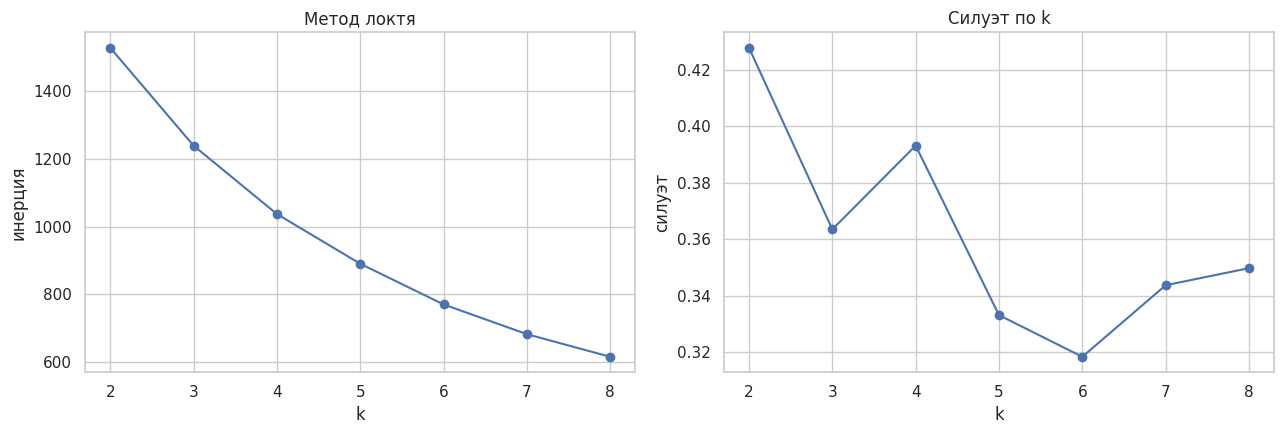

Выбранное k: 2


In [13]:
glass_rows = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_glass_s)
    glass_rows.append((k, model.inertia_, silhouette_score(X_glass_s, model.labels_)))
glass_k_table = pd.DataFrame(glass_rows, columns=["k", "inertia", "silhouette"])
print(glass_k_table.round(3).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(glass_k_table["k"], glass_k_table["inertia"], marker="o")
axes[0].set_xlabel("k"); axes[0].set_ylabel("инерция"); axes[0].set_title("Метод локтя")
axes[1].plot(glass_k_table["k"], glass_k_table["silhouette"], marker="o")
axes[1].set_xlabel("k"); axes[1].set_ylabel("силуэт"); axes[1].set_title("Силуэт по k")
plt.tight_layout(); plt.show()
glass_k = int(glass_k_table.loc[glass_k_table["silhouette"].idxmax(), "k"])
glass_km = KMeans(n_clusters=glass_k, n_init=10, random_state=RANDOM_STATE)
glass_labels = glass_km.fit_predict(X_glass_s)
print("Выбранное k:", glass_k)


**Вывод:**

Максимальный силуэт достигается при $k=2$ (около 0.428), поэтому выбрано два кластера. По инерции заметно снижение при малых $k$, но единственного очевидного излома нет. Разбиение неравномерное, поэтому результат стоит трактовать как рабочую группировку, а не как доказательство существования ровно двух типов стекла.


### Задание 5.3. Интерпретация кластеров

Опишите полученные кластеры: их размеры и средние значения признаков. Какие группы объектов получились и как бы вы их назвали содержательно?

In [14]:
glass_sizes = pd.Series(glass_labels).value_counts().sort_index().rename("size")
glass_means = X_glass.groupby(glass_labels).mean().round(3)
print(glass_sizes.to_string())
print(glass_means.to_string())


0     34
1    180
      RI      Na    Mg     Al      Si      K     Ca     Ba     Fe
0  1.516  14.523  0.54  2.189  72.845  0.605  8.254  0.952  0.011
1  1.519  13.197  3.09  1.304  72.614  0.477  9.090  0.028  0.066


**Вывод:**

Кластер 0 содержит 34 образца: в среднем у них больше натрия, алюминия и бария, но меньше магния. Кластер 1 содержит 180 образцов: в нём выше содержание магния, а бария почти нет. Условные названия — «барий- и алюминий-содержащие» и «магний-содержащие». Это описание средних профилей, не подтверждение реальных классов.


### Задание 5.4. Снижение размерности и визуализация

Примените PCA к своим данным. Сколько компонент нужно, чтобы объяснить ~80–90% дисперсии? Постройте объекты на первых двух компонентах и раскрасьте их по кластерам.

Доля дисперсии первых двух компонент: 0.507
Компонент для 80%: 5
Компонент для 90%: 6


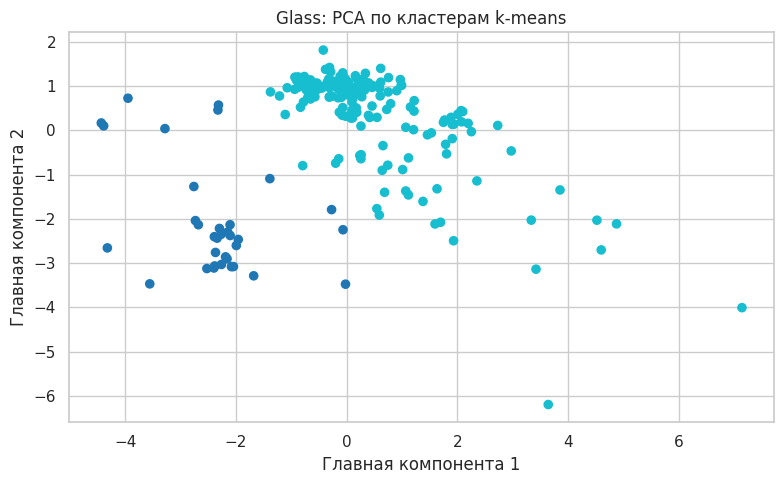

In [15]:
glass_pca = PCA().fit(X_glass_s)
glass_pca_2 = PCA(n_components=2).fit_transform(X_glass_s)
glass_cumulative = np.cumsum(glass_pca.explained_variance_ratio_)
print("Доля дисперсии первых двух компонент:", round(glass_cumulative[1], 3))
print("Компонент для 80%:", int(np.argmax(glass_cumulative >= 0.8) + 1))
print("Компонент для 90%:", int(np.argmax(glass_cumulative >= 0.9) + 1))
plt.figure(figsize=(8, 5))
plt.scatter(glass_pca_2[:, 0], glass_pca_2[:, 1], c=glass_labels, cmap="tab10", s=35)
plt.xlabel("Главная компонента 1"); plt.ylabel("Главная компонента 2")
plt.title("Glass: PCA по кластерам k-means")
plt.tight_layout(); plt.show()


**Вывод:**

Первые две компоненты объясняют около 50.7% дисперсии. Для объяснения не менее 80% нужны 5 компонент, а 90% — 6. Двумерная проекция удобна для просмотра, но не сохраняет всю структуру данных.


### Задание 5.5. Сравнение методов

Сравните k-means, агломеративную кластеризацию и DBSCAN на ваших данных по силуэту (и по числу найденных выбросов у DBSCAN). Какой метод дал более осмысленные группы?

In [16]:
glass_ag = AgglomerativeClustering(n_clusters=glass_k).fit_predict(X_glass_s)
glass_db = DBSCAN(eps=2.0, min_samples=5).fit_predict(X_glass_s)
glass_db_mask = glass_db != -1
glass_db_n = len(set(glass_db[glass_db_mask]))
glass_db_sil = silhouette_score(X_glass_s[glass_db_mask], glass_db[glass_db_mask]) if glass_db_n > 1 else np.nan
glass_results = pd.DataFrame([
    ("k-means", len(np.unique(glass_labels)), silhouette_score(X_glass_s, glass_labels), 0),
    ("Агломеративная", len(np.unique(glass_ag)), silhouette_score(X_glass_s, glass_ag), 0),
    ("DBSCAN", glass_db_n, glass_db_sil, int((~glass_db_mask).sum()))
], columns=["Метод", "Кластеров", "Силуэт", "Выбросов"])
print(glass_results.round(3).to_string(index=False))
run = wandb.init(project="apml-course", name="glass-clustering", config={"dataset": "glass.csv", "k": glass_k, "dbscan_eps": 2.0, "min_samples": 5})
wandb.log({"glass_kmeans_silhouette": float(glass_results.loc[0, "Силуэт"]), "glass_agglomerative_silhouette": float(glass_results.loc[1, "Силуэт"]), "glass_dbscan_silhouette_without_noise": float(glass_db_sil), "glass_dbscan_noise": int((~glass_db_mask).sum()), "glass_k": glass_k})
run.finish()


         Метод  Кластеров  Силуэт  Выбросов
       k-means          2   0.428         0
Агломеративная          2   0.450         0
        DBSCAN          2   0.495        24


**Резюме:**

Для `glass.csv` стандартизированы девять признаков, а `Type` не участвовал в обучении. По силуэту выбран k-means с $k=2$ (0.428); агломеративная кластеризация дала 0.450. DBSCAN при `eps=2.0` оставил 24 объекта шумом и разделил остальные на два кластера; силуэт на объектах без шума — 0.495, поэтому его нельзя напрямую сравнивать с метриками на всех 214 объектах. Для группировки всех образцов разумнее агломеративный метод, а DBSCAN полезен для поиска нетипичных наблюдений. Метрики эксперимента записываются в W&B.


---

## P.S. Как измерять качество кластеризации

У кластеризации нет «правильного ответа» как у классификации, поэтому используют два типа метрик.

- **Внутренние** (без разметки): **силуэт** (выше — лучше), индекс Калински–Харабаша, инерция. Они оценивают, насколько компактны и разделены кластеры.
- **Внешние** (если разметка есть, как в демо): **ARI**, **NMI** — насколько кластеры совпали с истинными классами. Нужны для проверки метода, но в реальной задаче метки обычно неизвестны.

**Главная ловушка.** Кластеры — это **не** классы. Алгоритм найдёт группы даже в случайном шуме, а найденная группа может не иметь бизнес-смысла. Поэтому кластеры всегда интерпретируют содержательно (профили, размеры) и проверяют на устойчивость (меняя seed, признаки, k) — а не принимают на веру только по цифре силуэта.

### Справочные материалы

- Кластеризация (scikit-learn): https://scikit-learn.org/stable/modules/clustering.html
- K-means: https://scikit-learn.org/stable/modules/clustering.html#k-means
- DBSCAN: https://scikit-learn.org/stable/modules/clustering.html#dbscan
- PCA: https://scikit-learn.org/stable/modules/decomposition.html#pca
- Метрики кластеризации: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation
- Интерактивная визуализация PCA: https://setosa.io/ev/principal-component-analysis/